# Phase 11 CLEAN-v3 KUB Failure Analysis — Visual Comparison Dashboard

**DESCRIPTIVE SINGLE-SEED FAILURE ANALYSIS**
**NO WINNER**
**NO SIGNIFICANCE TESTING**

---

**Model:** Gemini 3.8 Flash Medium · **Date:** 2026-09-21
**Manifest:** `phase4_v3` · **Taxonomy:** `kub_size_clean_v3_v1` · **Split:** KUB VAL (280)

> **READ-ONLY VISUALIZATION COMPANION.** This notebook exists to make the four-model KUB
> failure comparison easy to understand visually. It is sourced **only** from already-frozen
> Phase-11 tables and audits.
>
> No training · no inference · no threshold changes · no scientific recomputation ·
> no TEST access · no winner/rank/superiority claim · Phase 12 not started.
>
> **Fixed model order everywhere (descriptive, NOT a ranking):**
> **UNet → Attention U-Net → UNet++ → DeepLabV3+**


## 2. Scope and Governance

| Rule | Status |
|---|---|
| Source | frozen Phase-11 tables/audits only |
| Training epochs | **0** |
| Inference passes | **0** |
| Optimizer steps | **0** |
| Threshold changes | **0** |
| Scientific parameter changes | **0** |
| Winner / rank / best-model claim | **NONE** |
| Statistical significance testing | **NONE** |
| TEST image/mask/content reads | **0** |
| Phase 12 | **NOT STARTED** |

Model ordering is fixed and identical in every figure — the dashboard is descriptive, not a
ranking.


In [1]:
%matplotlib inline
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image as IPImage, display

pd.set_option('display.max_rows', None); pd.set_option('display.max_columns', None)
pd.set_option('display.width', None); pd.set_option('display.max_colwidth', None)

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_11_failure_analysis' / 'code'))
import phase11_failure_visual_dashboard as dv

print('Fixed model order:', dv.MODELS)
print('Figure directory :', dv.FIGDIR)
print()
print(dv.SUBTITLE)


Fixed model order: ['UNet', 'Attention U-Net', 'UNet++', 'DeepLabV3+']
Figure directory : D:\Softfors\jup\reports\figures\phase11_clean_v3_failure_visual_dashboard

DESCRIPTIVE SINGLE-SEED FAILURE ANALYSIS
NO WINNER
NO SIGNIFICANCE TESTING


## 3. Dashboard Summary Table

Compact descriptive overview. **No `rank` / `winner` / `best_model` / `score` / `tier`
columns exist by design.**


In [2]:
summary_tbl = dv.dashboard_summary_table()
display(summary_tbl)
print()
print('Overall Phase-10 VAL Dice is the single-seed descriptive Phase-10 value.')
print('FULL_FIELD / ROI Dice are Phase-11 regime-stratified means (FULL_FIELD n=103, ROI n=177).')


,Model,Overall Phase-10 VAL Dice,FULL_FIELD Dice,ROI Dice,Object Recall,Empty Predictions,Multi-component Complete,Multi-component Partial,Multi-component Miss
0,UNet,0.740613,0.596460,0.824499,0.896341,8,30,16,3
1,Attention U-Net,0.752513,0.631730,0.822799,0.923780,3,33,12,4
2,UNet++,0.764160,0.645474,0.833225,0.914634,6,33,11,5
3,DeepLabV3+,0.750914,0.559086,0.862543,0.881098,11,27,16,6



Overall Phase-10 VAL Dice is the single-seed descriptive Phase-10 value.
FULL_FIELD / ROI Dice are Phase-11 regime-stratified means (FULL_FIELD n=103, ROI n=177).


## 4. Plot 1 — Empty Predictions by Model


saved: empty_predictions_by_model.png


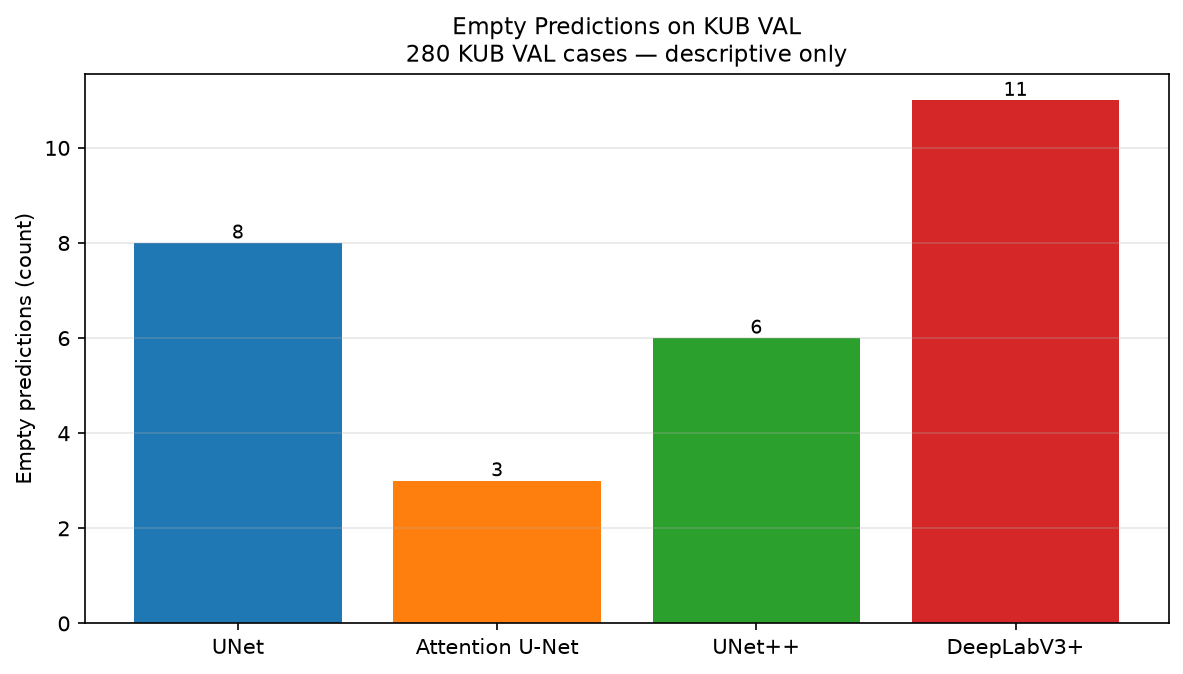


Values (from phase11_clean_v3_failure_summary_by_model.csv):
model
UNet                8
Attention U-Net     3
UNet++              6
DeepLabV3+         11


In [3]:
p = dv.plot_empty_predictions()
print('saved:', p.name)
display(IPImage(filename=str(p)))
print()
print('Values (from phase11_clean_v3_failure_summary_by_model.csv):')
print(dv.load_summary().set_index('model').loc[dv.MODELS, 'empty_predictions'].to_string())


## 5. Plot 2 — Object Recall by Model

`EVALUATION_512` component space · 8-connectivity · `>= 1 px` overlap.
The tallest bar is **not** called "best model" — only
"highest observed object recall in this single-seed analysis".


saved: object_recall_by_model.png


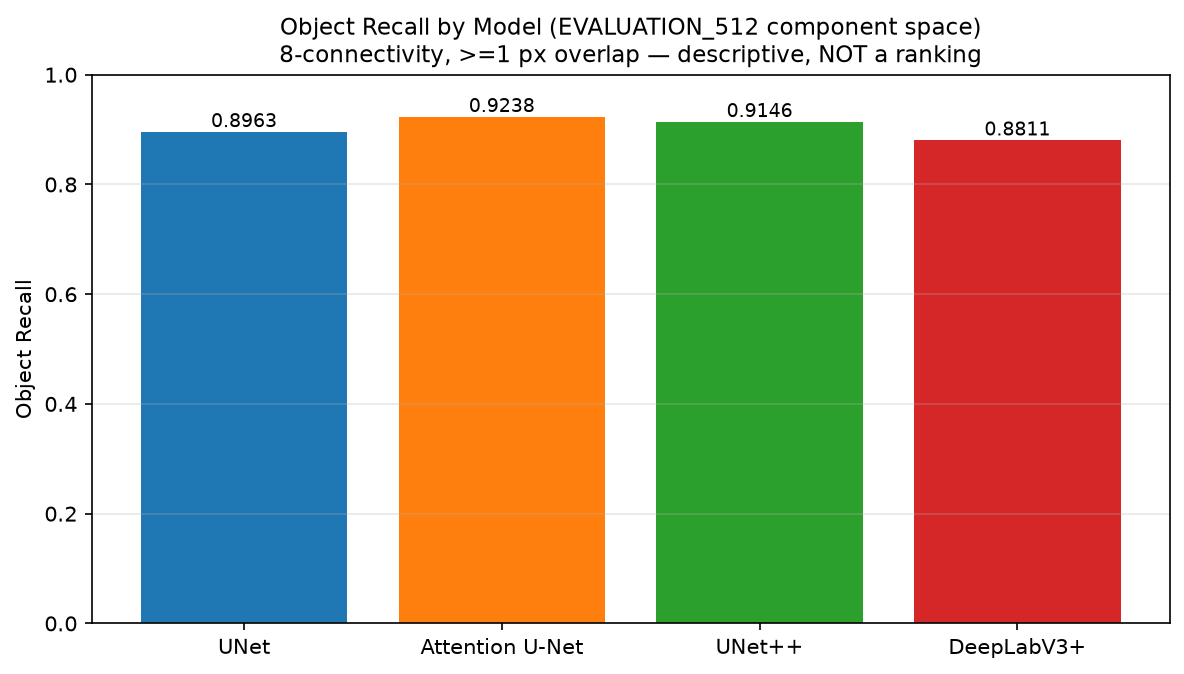


                 object_recall
model                         
UNet                  0.896341
Attention U-Net       0.923780
UNet++                0.914634
DeepLabV3+            0.881098


In [4]:
p = dv.plot_object_recall()
print('saved:', p.name)
display(IPImage(filename=str(p)))
print()
print(dv.load_summary().set_index('model').loc[dv.MODELS, ['object_recall']].to_string())


## 6. Plot 3 — ROI vs FULL_FIELD Dice

One of the most important plots. Caption: **FULL_FIELD n=103 · ROI n=177**.

> The regime gap is **observed across all four models**.
> This does **not** mean "ROI is superior", and it is **not** evidence that "regional
> processing solves the problem" — existing ROI samples and oracle regional processing are
> **not** the same experiment.


saved: roi_vs_fullfield_dice.png


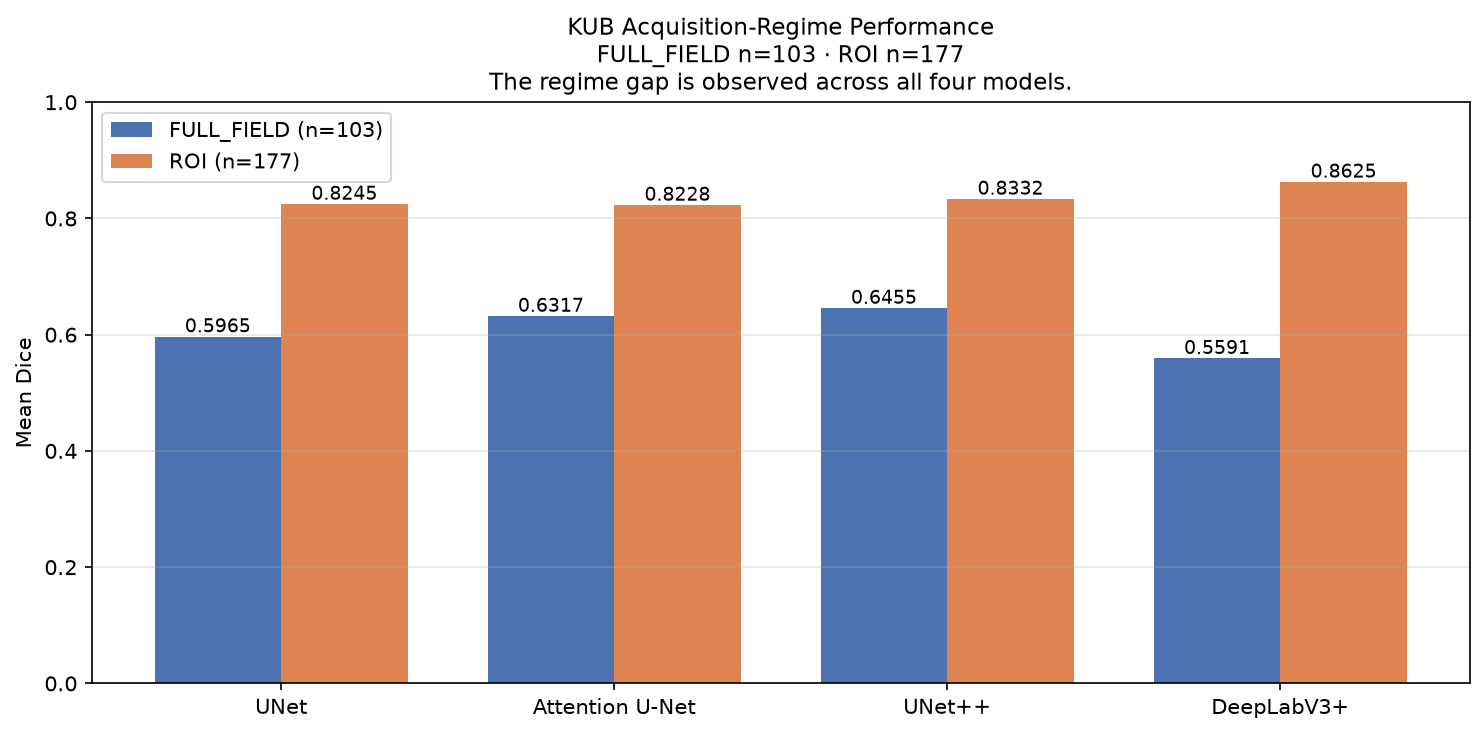

,Model,FULL_FIELD Dice,ROI Dice
0,UNet,0.596460,0.824499
1,Attention U-Net,0.631730,0.822799
2,UNet++,0.645474,0.833225
3,DeepLabV3+,0.559086,0.862543


In [5]:
p = dv.plot_roi_vs_fullfield()
print('saved:', p.name)
display(IPImage(filename=str(p)))
reg = dv.load_regime()
tbl = pd.DataFrame({'Model': dv.MODELS,
                    'FULL_FIELD Dice': [reg['FULL_FIELD'][m] for m in dv.MODELS],
                    'ROI Dice': [reg['ROI'][m] for m in dv.MODELS]})
display(tbl)


## 7. Plot 4 — ROI–FULL_FIELD Dice Gap

**DESCRIPTIVE ACQUISITION-REGIME GAP — NOT an oracle-ROI treatment effect.**


saved: roi_fullfield_gap.png


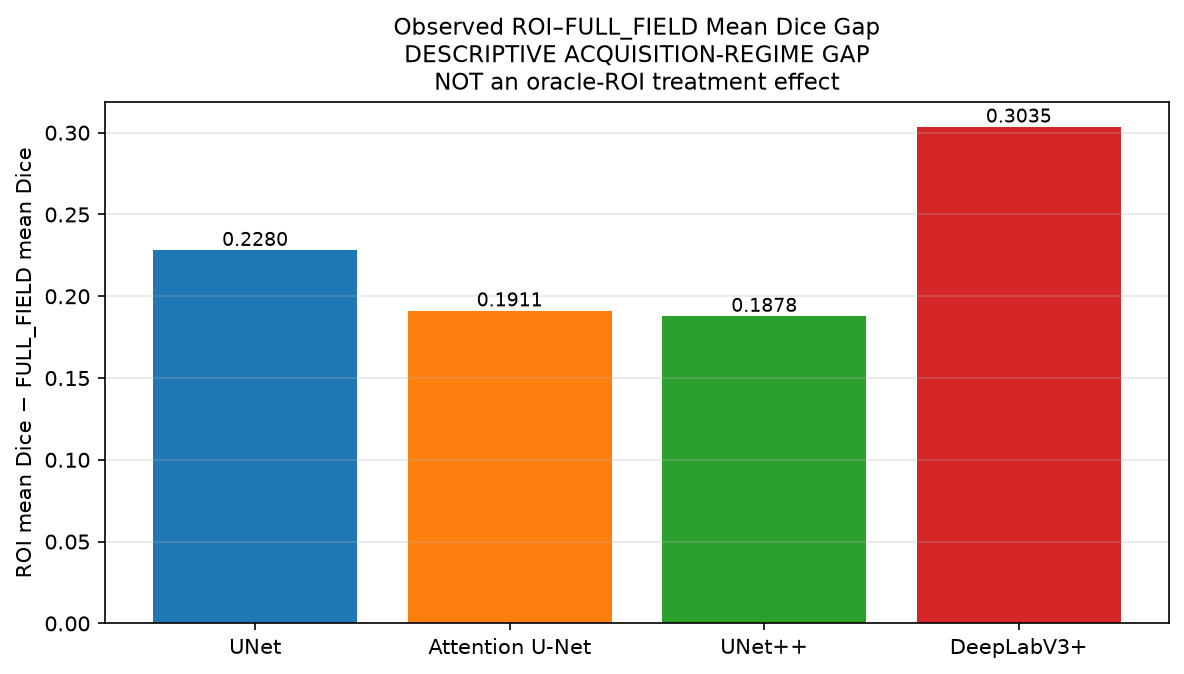

,Model,ROI minus FULL_FIELD
0,UNet,0.228039
1,Attention U-Net,0.191069
2,UNet++,0.187751
3,DeepLabV3+,0.303457


mean gap across models: 0.227579


In [6]:
p = dv.plot_regime_gap()
print('saved:', p.name)
display(IPImage(filename=str(p)))
reg = dv.load_regime()
gaps = pd.DataFrame({'Model': dv.MODELS,
                     'ROI minus FULL_FIELD': [reg['ROI'][m] - reg['FULL_FIELD'][m] for m in dv.MODELS]})
display(gaps)
print('mean gap across models: %.6f' % gaps['ROI minus FULL_FIELD'].mean())


## 8. Plot 5 — Multi-Component Case Detection Outcomes

native GT membership · 8-connectivity.


saved: multicomponent_outcomes.png


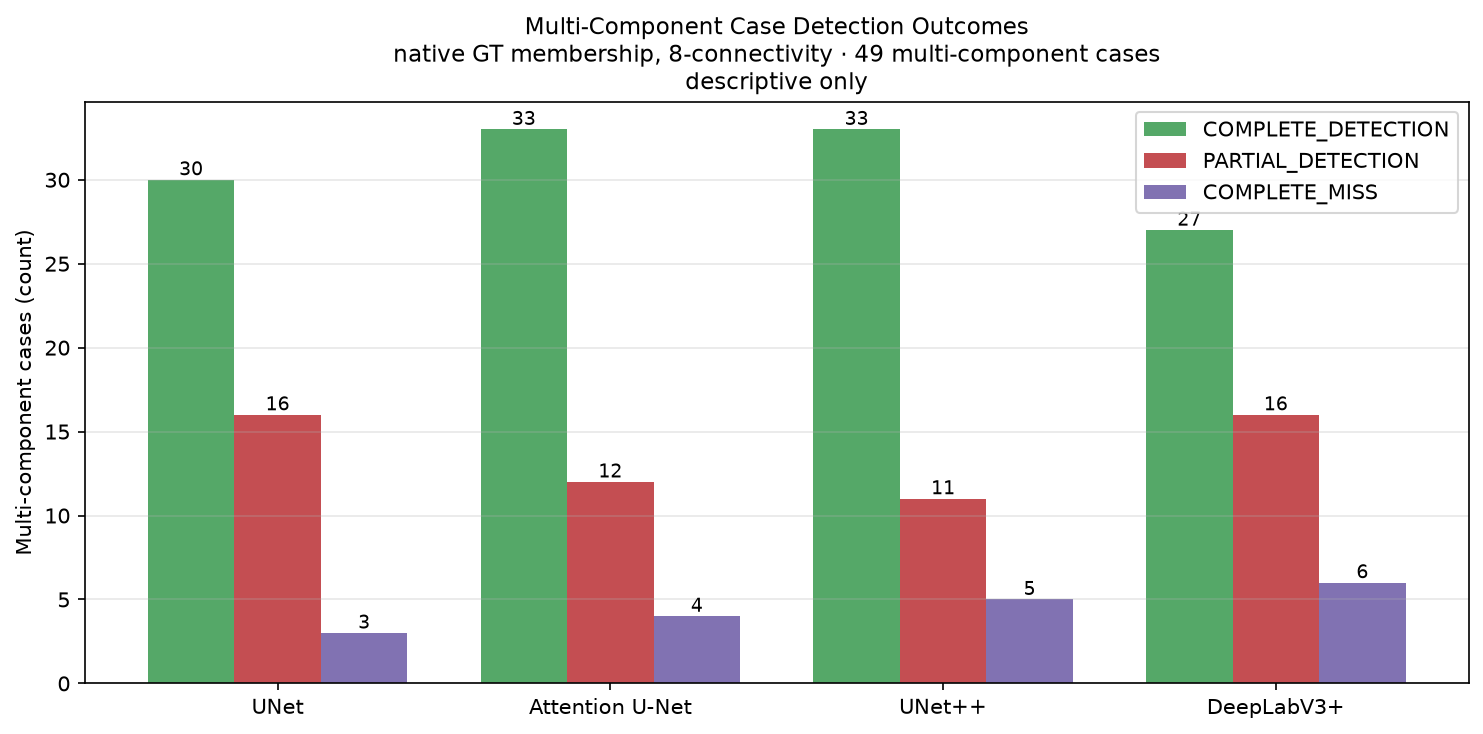

,model,multicomponent_cases,COMPLETE_DETECTION,PARTIAL_DETECTION,COMPLETE_MISS
0,UNet,49,30,16,3
1,Attention U-Net,49,33,12,4
2,UNet++,49,33,11,5
3,DeepLabV3+,49,27,16,6


In [7]:
p = dv.plot_multicomponent()
print('saved:', p.name)
display(IPImage(filename=str(p)))
m = dv.load_multi()
display(m[['model','multicomponent_cases','COMPLETE_DETECTION','PARTIAL_DETECTION','COMPLETE_MISS']])


## 9. Plot 6 — Missed GT Components by Model

`EVALUATION_512` space · 8-connectivity · `>= 1 px` minimum overlap.


saved: missed_components_by_model.png


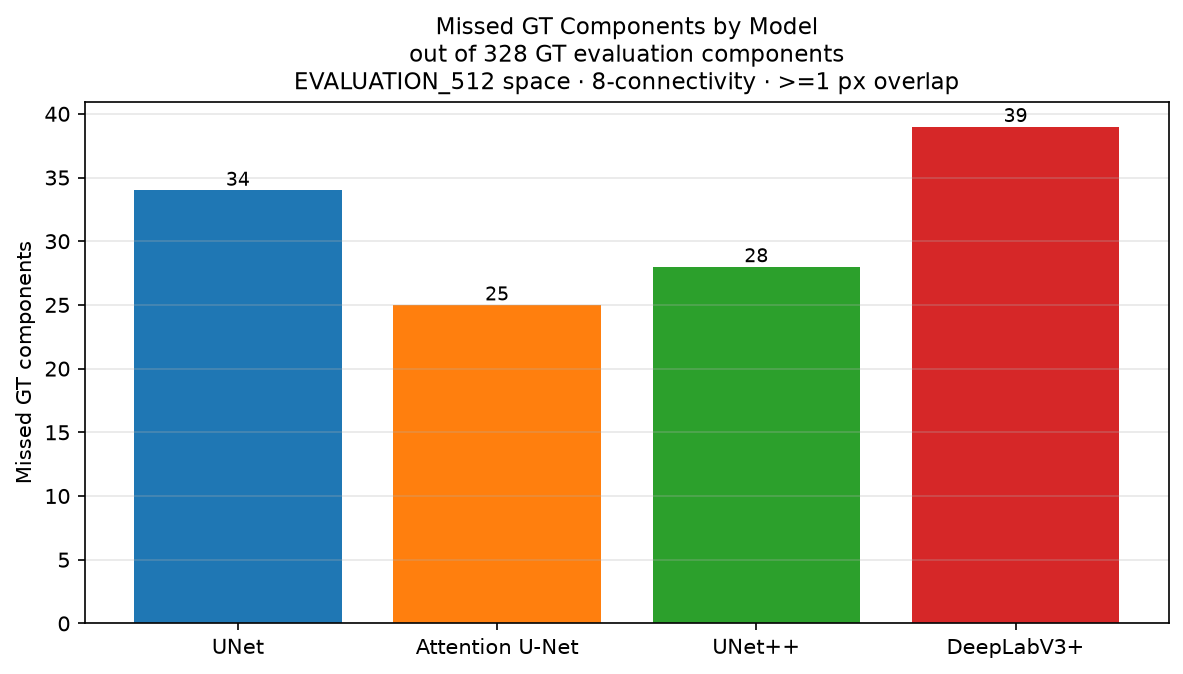

,Model,missed_components,gt_eval_components
0,UNet,34,328
1,Attention U-Net,25,328
2,UNet++,28,328
3,DeepLabV3+,39,328


In [8]:
p = dv.plot_missed_components()
print('saved:', p.name)
display(IPImage(filename=str(p)))
s = dv.load_summary().set_index('model')
display(pd.DataFrame({'Model': dv.MODELS,
                      'missed_components': [int(s.loc[m,'missed_components']) for m in dv.MODELS],
                      'gt_eval_components': [int(s.loc[m,'gt_eval_components']) for m in dv.MODELS]}))


## 10. Plot 7 — Model-Specific Low-Dice Q10 Cutoffs

Each cutoff is defined from **that model's own** Dice distribution (bottom decile,
`np.quantile(..., 0.10)` linear, float64). **A larger cutoff does NOT mean a better model.**


saved: low_dice_q10_by_model.png


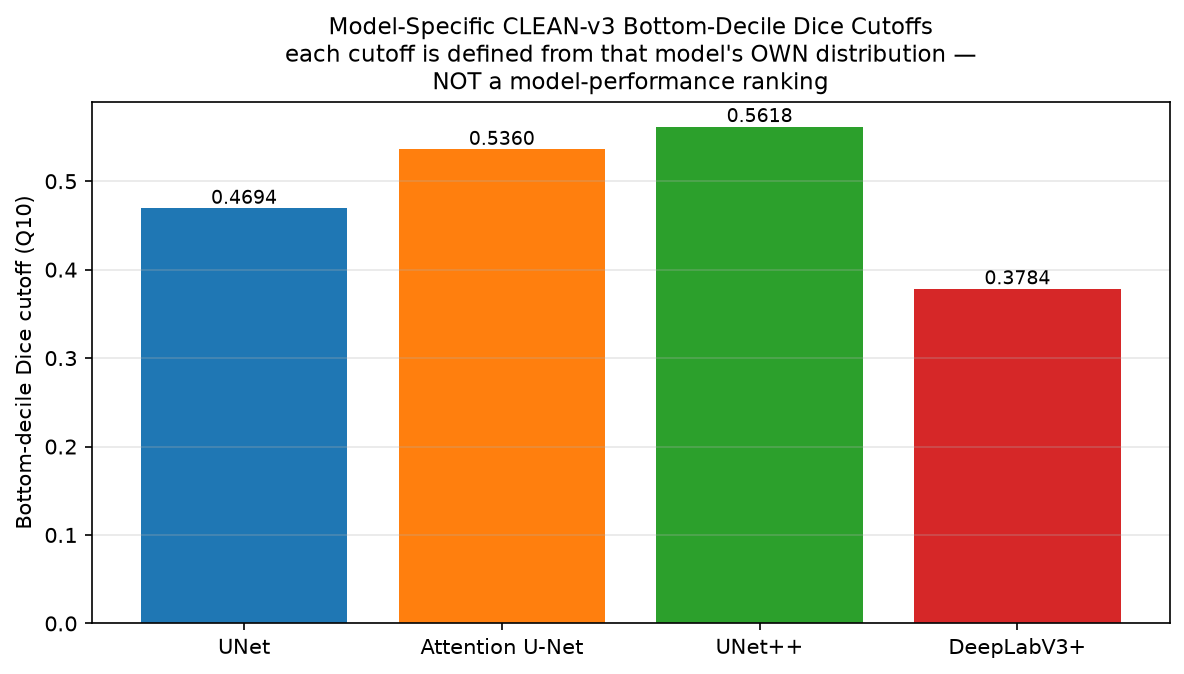

,Model,q10_cutoff,count_le_cutoff
0,UNet,0.469394,28
1,Attention U-Net,0.536024,28
2,UNet++,0.561806,28
3,DeepLabV3+,0.378429,28



This is NOT a model-performance ranking.


In [9]:
p = dv.plot_low_dice_q10()
print('saved:', p.name)
display(IPImage(filename=str(p)))
q10 = dv.load_low_dice_q10(); cnt = dv.load_low_dice_counts()
display(pd.DataFrame({'Model': dv.MODELS,
                      'q10_cutoff': [q10[m] for m in dv.MODELS],
                      'count_le_cutoff': [cnt[m] for m in dv.MODELS]}))
print()
print('This is NOT a model-performance ranking.')


## 11. Plot 8 — Shared Failure Distribution

`low_model_count` = how many of the four models flag the case as bottom-decile Dice.
`low_model_count = 4` corresponds to **ALL_FOUR_LOW = 12 / 280**.


saved: shared_failure_low_model_count.png


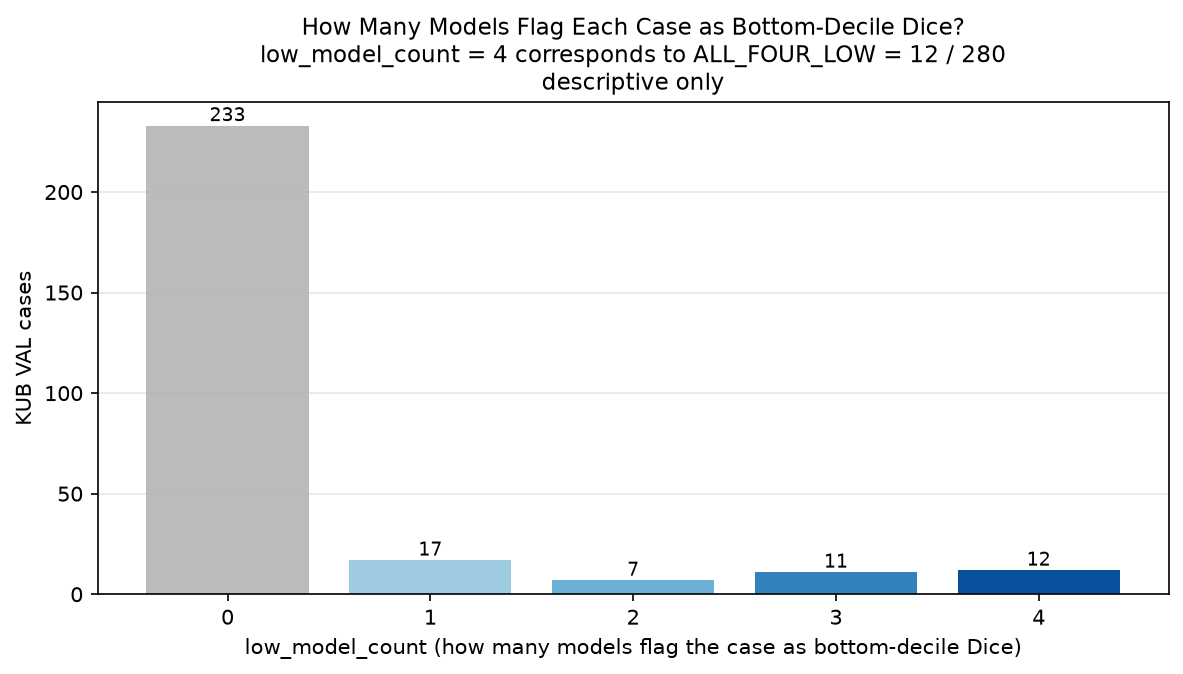

,low_model_count,cases
0,0,233
1,1,17
2,2,7
3,3,11
4,4,12


ALL_FOUR_LOW: 12 / 280


In [10]:
p = dv.plot_shared_failure()
print('saved:', p.name)
display(IPImage(filename=str(p)))
d = dv.load_paired()
dist = pd.DataFrame({'low_model_count': list(range(5)),
                     'cases': [int((d['low_model_count']==i).sum()) for i in range(5)]})
display(dist)
print('ALL_FOUR_LOW:', int(d['ALL_FOUR_LOW'].sum()), '/ 280')


## 12. Plot 9 — False-Positive Component Burden

`EVALUATION_512` component space. **UNet++ CLEAN-v3 Q90 = 5.0** is the
`HIGH_FP_DECILE` **anchor-only** cutoff — it is **not** a universal FP threshold; the other
models are descriptive.


saved: fp_component_burden.png


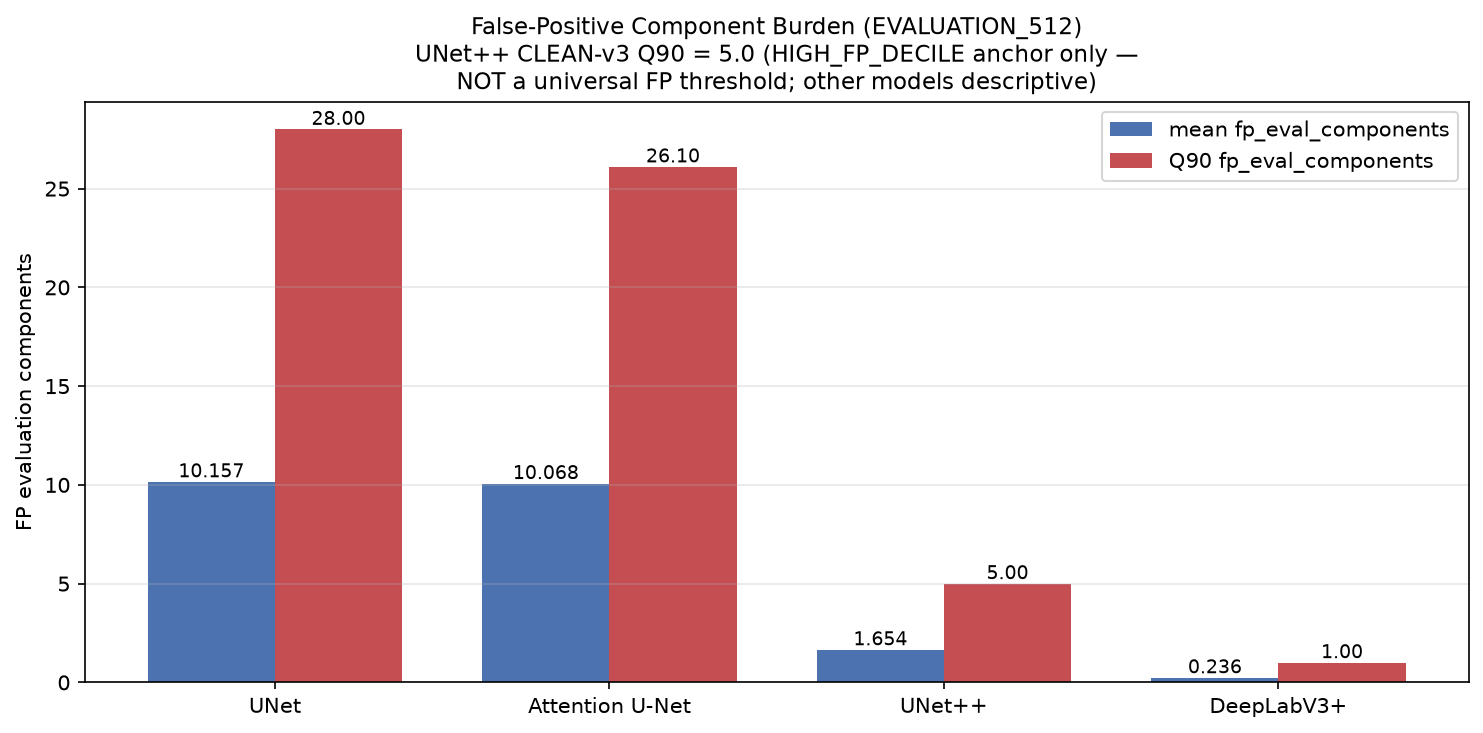

,model,mean,median,q90,max
0,UNet,10.157143,6.0,28.0,113
1,Attention U-Net,10.067857,6.0,26.1,96
2,UNet++,1.653571,1.0,5.0,12
3,DeepLabV3+,0.235714,0.0,1.0,4


In [11]:
p = dv.plot_fp_burden()
print('saved:', p.name)
display(IPImage(filename=str(p)))
display(dv.load_fp()[['model','mean','median','q90','max']])


## 13. Plot 10 — HD95 Validity / Boundary Burden

Invalid HD95 cases (empty prediction / empty GT) are **flagged, never silently dropped**.


saved: hd95_validity.png


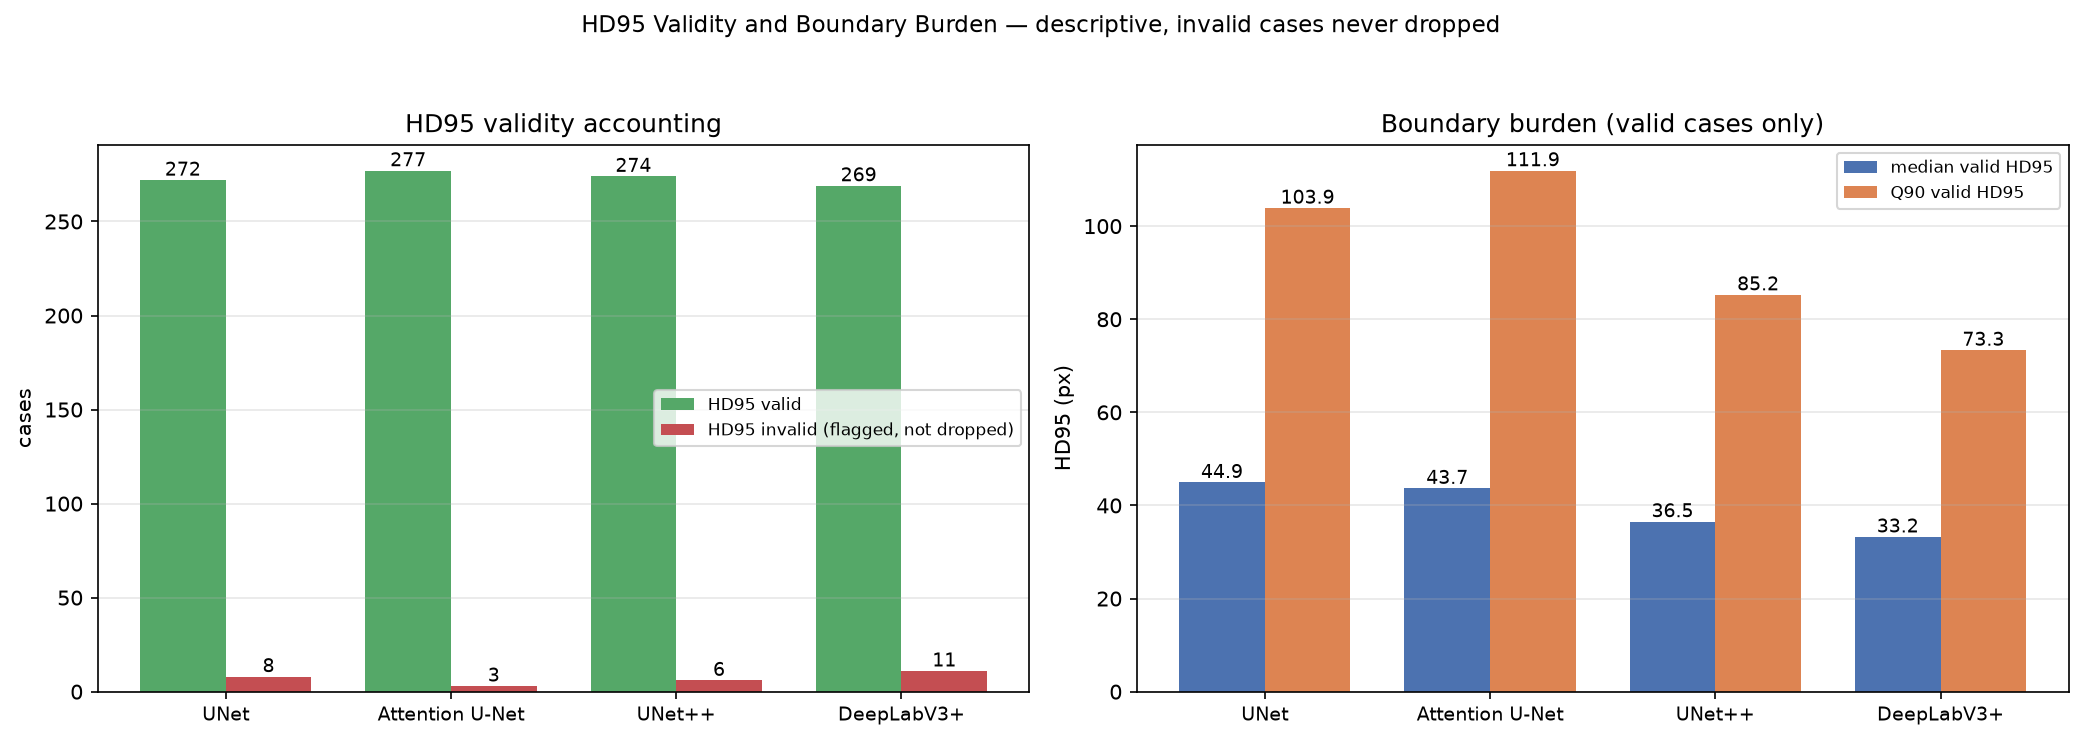

,model,n_valid,n_invalid,valid_rate,median_hd95,q90_hd95_valid
0,UNet,272,8,0.971429,44.932079,103.858622
1,Attention U-Net,277,3,0.989286,43.668065,111.901276
2,UNet++,274,6,0.978571,36.509467,85.240955
3,DeepLabV3+,269,11,0.960714,33.234758,73.347546


In [12]:
p = dv.plot_hd95()
print('saved:', p.name)
display(IPImage(filename=str(p)))
display(dv.load_hd95()[['model','n_valid','n_invalid','valid_rate','median_hd95','q90_hd95_valid']])


## 14. Plot 11 — Architecture Disagreement

`dice_range = max model Dice − min model Dice` — **continuous, no binary threshold.**
Top-4 cases labelled `DESCRIPTIVE_DISAGREEMENT_DIAGNOSTIC_ONLY`.


saved: architecture_disagreement_top4.png


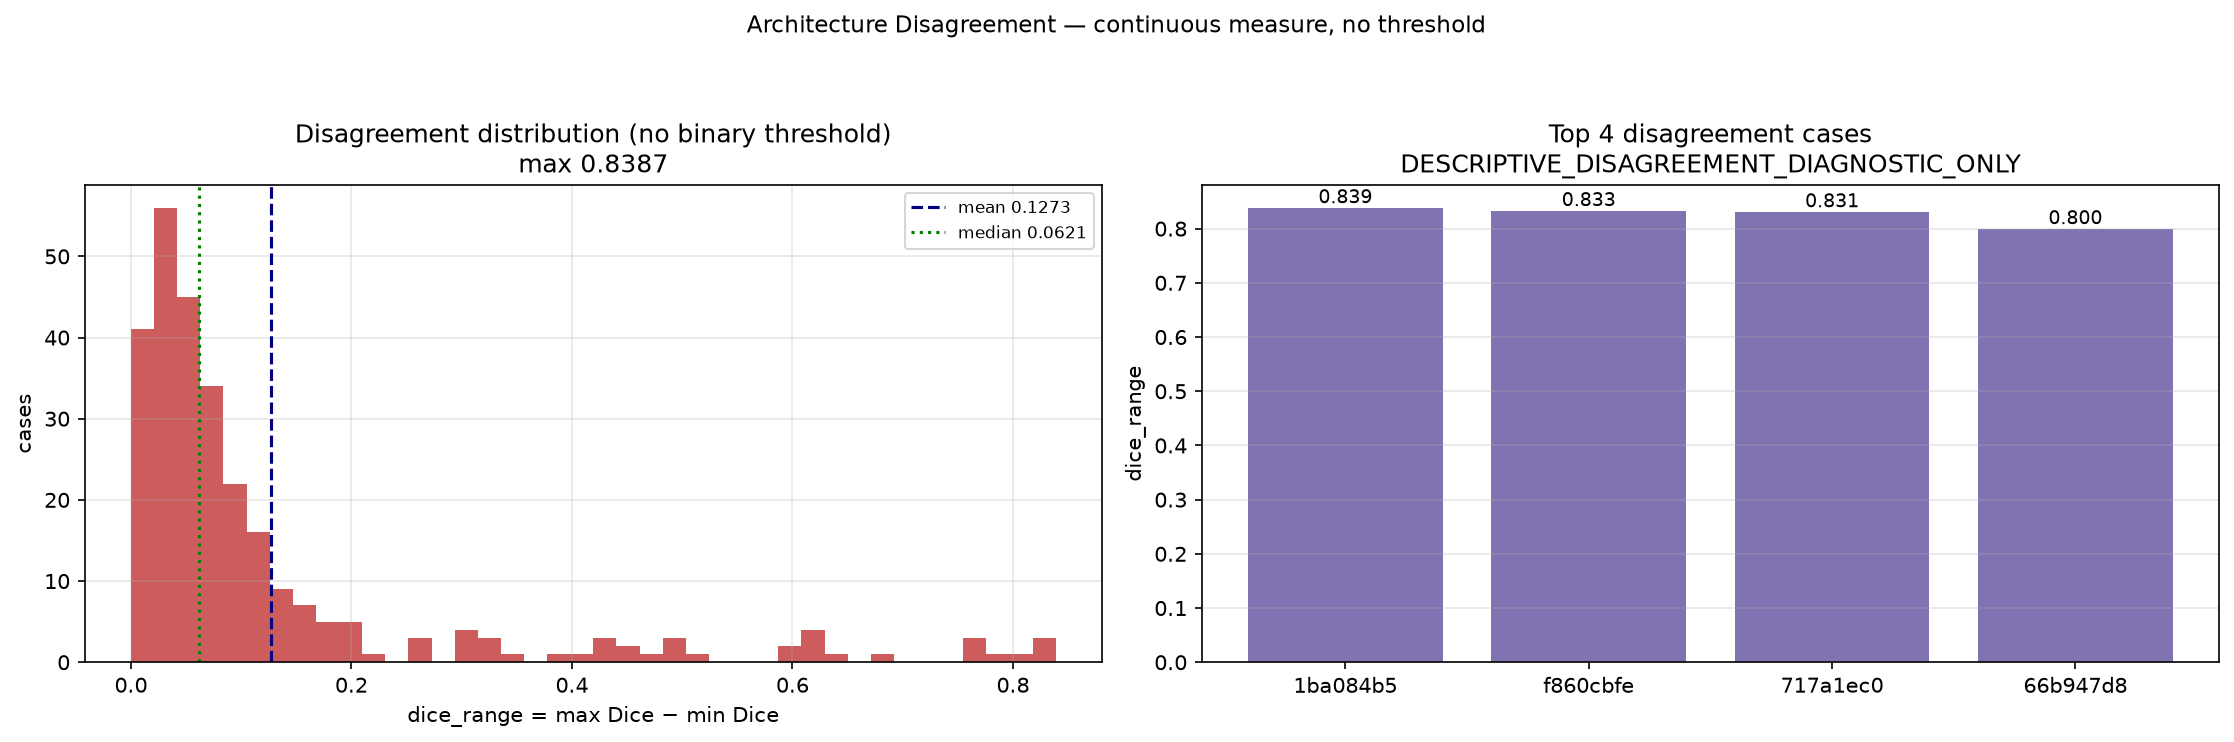

dice_range mean 0.127297 · median 0.062132 · max 0.838710


,sample_id,dice_min,dice_max,dice_range
0,1ba084b5439ffee651b4f5e0697e2209,5.555556e-09,0.838710,0.838710
1,f860cbfe7c79e5772795a64bac5de7e7,3.125000e-09,0.833333,0.833333
2,717a1ec0a082fae24e2341341ca83e77,2.439024e-09,0.831169,0.831169
3,66b947d8ead11ae1260bc3142ca1707d,7.142857e-09,0.800000,0.800000


In [13]:
p = dv.plot_disagreement()
print('saved:', p.name)
display(IPImage(filename=str(p)))
d = dv.load_disagreement()
print('dice_range mean %.6f · median %.6f · max %.6f' % (d.dice_range.mean(), d.dice_range.median(), d.dice_range.max()))
display(dv.load_top_disagreement(4)[['sample_id','dice_min','dice_max','dice_range']])


## 15. Plot 12 — Hard-Case Cohort Composition

Deterministic historical-style diagnostic cohort (UNet++ anchor). **Prediction-dependent
diagnostic cohort — NOT a prevalence estimate.**


saved: hard_case_composition.png


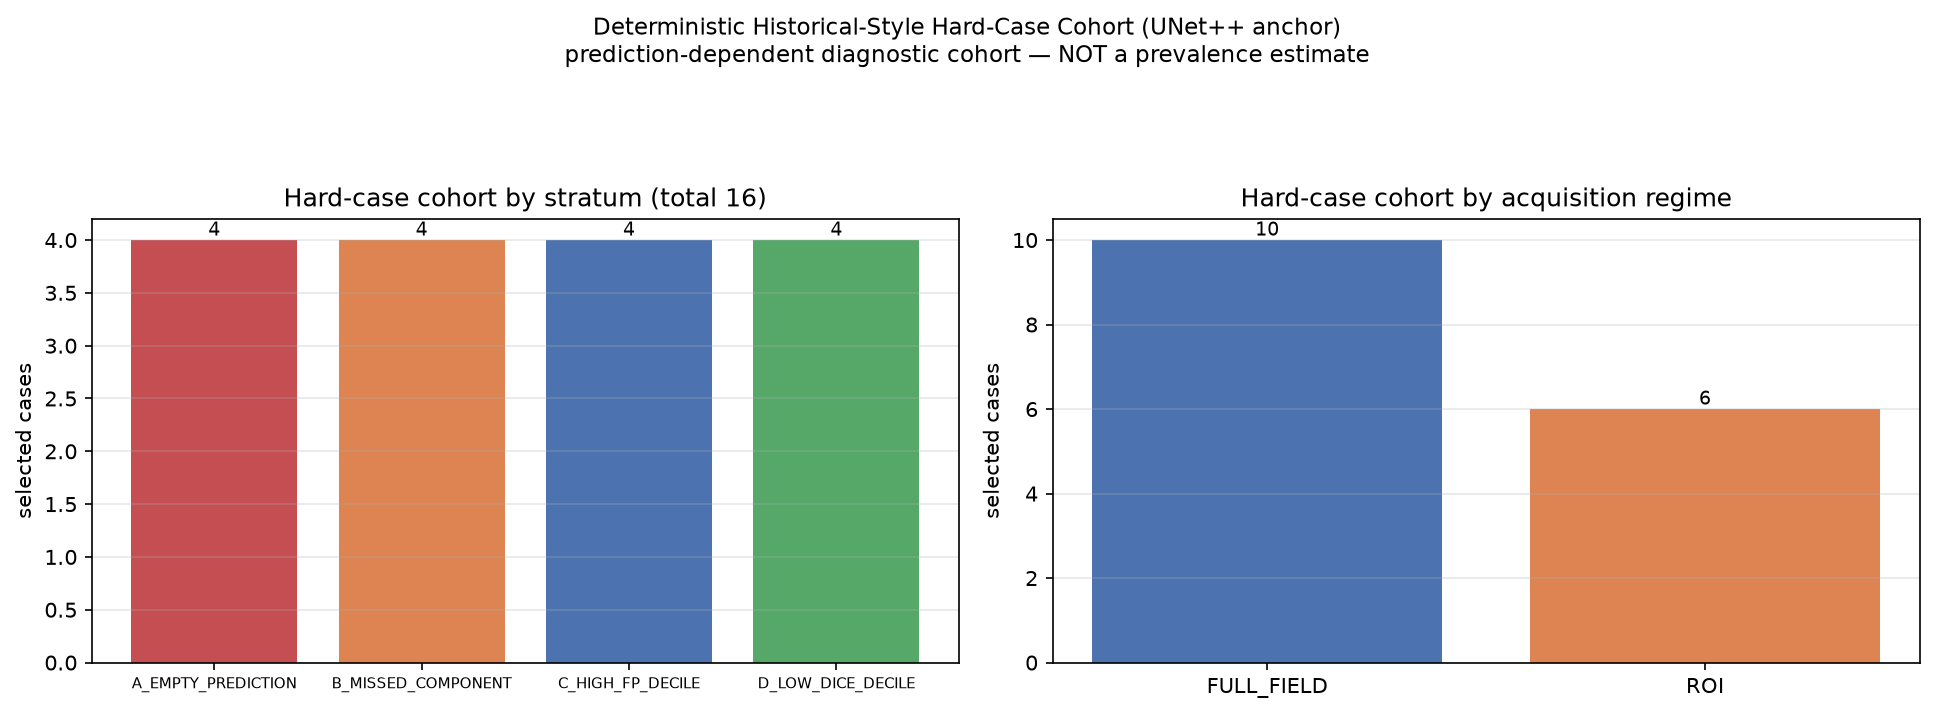

,stratum,cases
0,A_EMPTY_PREDICTION,4
1,B_MISSED_COMPONENT,4
2,C_HIGH_FP_DECILE,4
3,D_LOW_DICE_DECILE,4


,acquisition,cases
0,FULL_FIELD,10
1,ROI,6


In [14]:
p = dv.plot_hard_case_composition()
print('saved:', p.name)
display(IPImage(filename=str(p)))
h = dv.load_hard_case()
display(h['stratum'].value_counts().rename_axis('stratum').reset_index(name='cases'))
display(h['acquisition'].value_counts().rename_axis('acquisition').reset_index(name='cases'))


## 16. Phase-11 → Phase-12 Bridge Summary

Dimensions with a **qualitative / MIXED** verdict are shown **as a table**, not as a
fabricated bar height. No qualitative label is converted into an arbitrary numeric score.


In [15]:
display(dv.bridge_summary_table())
print()
print('Verdict counts:', dv.load_bridge()['verdict'].value_counts().to_dict())
print('Qualitative/MIXED dimensions remain tabular only.')


,evidence,value,verdict
0,FULL_FIELD vs ROI mean-Dice gap,0.2276,MOTIVATES_ORACLE_ROI_TEST
1,FULL_FIELD mean Dice (per model),"{'Attention U-Net': 0.6317, 'DeepLabV3+': 0.5591, 'UNet': 0.5965, 'UNet++': 0.6455}",MOTIVATES_ORACLE_ROI_TEST
2,FULL_FIELD TINY components with incomplete/missed detection,"72 native TINY components; components in partially/missed cases per model: {'UNet': 29, 'Attention U-Net': 22, 'UNet++': 20, 'DeepLabV3+': 33}",MOTIVATES_ORACLE_ROI_TEST
3,FULL_FIELD SMALL components with incomplete/missed detection,"28 native SMALL components; components in partially/missed cases per model: {'UNet': 10, 'Attention U-Net': 8, 'UNet++': 7, 'DeepLabV3+': 10}",MOTIVATES_ORACLE_ROI_TEST
4,multi-component partial/miss cases (per model),"{'UNet': 19, 'Attention U-Net': 16, 'UNet++': 16, 'DeepLabV3+': 22}",MOTIVATES_ORACLE_ROI_TEST
5,empty predictions (FULL_FIELD vs ROI),FULL_FIELD 3-11 per model; ROI 0-1 per model,MOTIVATES_ORACLE_ROI_TEST
6,HD95 valid median (per model),"{'Attention U-Net': 43.67, 'DeepLabV3+': 33.23, 'UNet': 44.93, 'UNet++': 36.51}",MIXED
7,FP component burden (mean per case),"{'Attention U-Net': 10.068, 'DeepLabV3+': 0.236, 'UNet': 10.157, 'UNet++': 1.654}",MIXED
8,ALL_FOUR_LOW shared-failure cases,12/280,MOTIVATES_ORACLE_ROI_TEST
9,cases where >=3 models lose components,23,MOTIVATES_ORACLE_ROI_TEST



Verdict counts: {'MOTIVATES_ORACLE_ROI_TEST': 8, 'MIXED': 2}
Qualitative/MIXED dimensions remain tabular only.


## 17. Composite Failure Dashboard (reviewer overview)


saved: overall_failure_dashboard.png


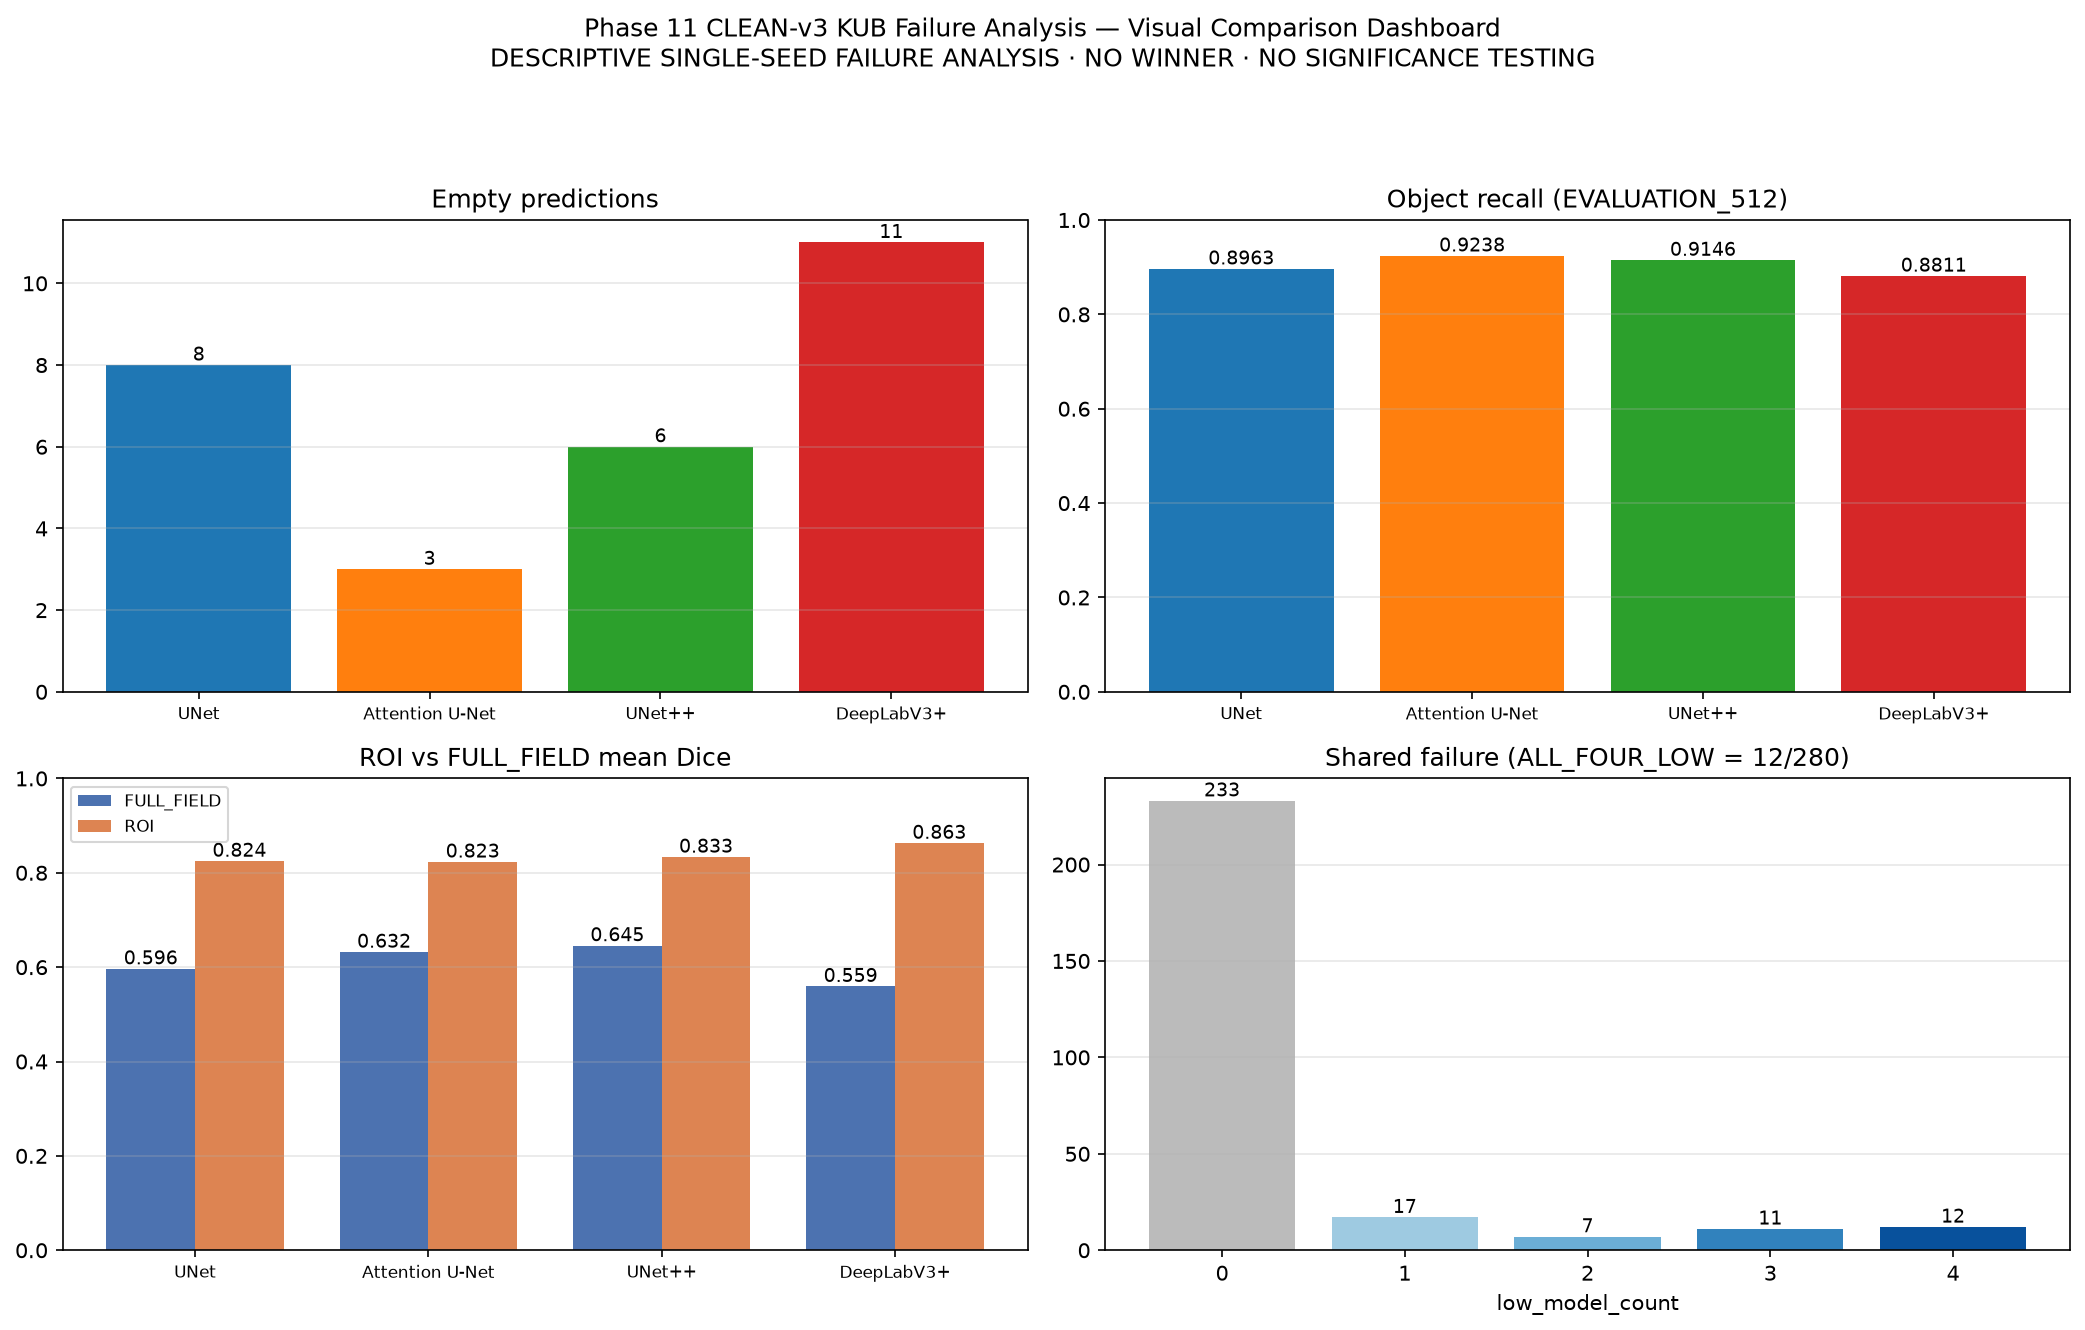

In [16]:
p = dv.plot_overall_dashboard()
print('saved:', p.name)
display(IPImage(filename=str(p)))


## 18. Interpretation

**What this dashboard supports (descriptive):**

- All four models show **lower FULL_FIELD mean Dice than ROI mean Dice** — the regime gap is
  observed across all four.
- **Failure burden differs by architecture** (empty predictions, missed components, and FP
  component burden are not uniform).
- **Some difficult cases are shared across all four models** — `ALL_FOUR_LOW = 12 / 280`.
- **Some cases show large architecture disagreement** (up to `dice_range ≈ 0.84`).
- **Empty predictions and missed components motivate testing regional resolution explicitly
  in Phase 12** — as a hypothesis to be tested, not an established result.

**What this dashboard does NOT support (and does not claim):**

- ✗ a winner or best model
- ✗ "statistically better" / "significant" (no significance testing has been performed)
- ✗ "ROI solves KUB"
- ✗ "the regional model will definitely work"

The existing ROI samples and the future oracle regional processing are **not** the same
experiment.


## 19. Artifact Registry


In [17]:
produced = {
 'overall_failure_dashboard.png': dv.FIGDIR/'overall_failure_dashboard.png',
 'empty_predictions_by_model.png': dv.FIGDIR/'empty_predictions_by_model.png',
 'object_recall_by_model.png': dv.FIGDIR/'object_recall_by_model.png',
 'roi_vs_fullfield_dice.png': dv.FIGDIR/'roi_vs_fullfield_dice.png',
 'roi_fullfield_gap.png': dv.FIGDIR/'roi_fullfield_gap.png',
 'multicomponent_outcomes.png': dv.FIGDIR/'multicomponent_outcomes.png',
 'missed_components_by_model.png': dv.FIGDIR/'missed_components_by_model.png',
 'low_dice_q10_by_model.png': dv.FIGDIR/'low_dice_q10_by_model.png',
 'shared_failure_low_model_count.png': dv.FIGDIR/'shared_failure_low_model_count.png',
 'fp_component_burden.png': dv.FIGDIR/'fp_component_burden.png',
 'hd95_validity.png': dv.FIGDIR/'hd95_validity.png',
 'architecture_disagreement_top4.png': dv.FIGDIR/'architecture_disagreement_top4.png',
 'hard_case_composition.png': dv.FIGDIR/'hard_case_composition.png',
}
missing = [k for k,v in produced.items() if not v.exists()]
assert not missing, f'missing figures: {missing}'
REG = dv.build_registry(produced)
rp = dv.save_registry(REG)
print(f'Saved registry: {rp.name} ({len(REG)} entries)')
display(REG)


Saved registry: phase11_clean_v3_failure_visual_dashboard_registry.csv (14 entries)


,artifact,type,source_table,SHA256,description
0,overall_failure_dashboard.png,figure,phase11_clean_v3_failure_summary_by_model.csv,ce0f4fa0233154d471d23ba7209497ec8baed9795b29a57e420d6500eb7d4b58,read-only descriptive Phase-11 failure visualisation
1,empty_predictions_by_model.png,figure,phase11_clean_v3_failure_summary_by_model.csv,cdf34b4537ada38becff5310cdc9d7316918cde79e7d0fee0ec2f800583ac318,read-only descriptive Phase-11 failure visualisation
2,object_recall_by_model.png,figure,phase11_clean_v3_failure_summary_by_model.csv,8c25f9c13db6c15aac2edd8c4e949356d1d0ce95b095e1d0365eb481e2babbce,read-only descriptive Phase-11 failure visualisation
3,roi_vs_fullfield_dice.png,figure,phase11_clean_v3_failure_by_acquisition.csv,2f3efa566aa3d4ae4863f2b1b04ae70e16f3b4697701e40bc73596e5c17ed72a,read-only descriptive Phase-11 failure visualisation
4,roi_fullfield_gap.png,figure,phase11_clean_v3_failure_by_acquisition.csv,6fe09fbbccc944f5a029f9765be22d8d6c579dc0109cd4aa235ad9e76ae54799,read-only descriptive Phase-11 failure visualisation
5,multicomponent_outcomes.png,figure,phase11_clean_v3_multicomponent_analysis.csv,f28827ee34d071ce869ed7c7388ee92c6363d7615fcd28f000cca8547d54d581,read-only descriptive Phase-11 failure visualisation
6,missed_components_by_model.png,figure,phase11_clean_v3_failure_summary_by_model.csv,917c28fa20de66e2fe6724c4810c71979702b8c3f7174dbd6a96aa58992855c3,read-only descriptive Phase-11 failure visualisation
7,low_dice_q10_by_model.png,figure,phase11_clean_v3_low_dice_decile_cutoffs.csv,eac67bdf1fcc16d9af95d58fa60e0e0803e6b3773a8498daee9da033201ea14d,read-only descriptive Phase-11 failure visualisation
8,shared_failure_low_model_count.png,figure,phase11_clean_v3_paired_case_failure_summary.csv,98eb5f812f366fca2f2e0cead242c46a8ba6d9fcbcc538e94f32e82e04935a54,read-only descriptive Phase-11 failure visualisation
9,fp_component_burden.png,figure,phase11_clean_v3_fp_burden_summary.csv,618a986b581e6e596008b58e0dc8683de9752616969c83fac1ddcf33231bf92e,read-only descriptive Phase-11 failure visualisation


## 20. Stop Boundary


In [18]:
print('=== DASHBOARD BOUNDARY ===')
print('Training epochs            : 0')
print('Inference passes           : 0')
print('Optimizer steps            : 0')
print('Threshold changes          : 0')
print('Scientific recomputation   : NONE (frozen tables only)')
print('Source tables modified     : NONE')
print('TEST image/mask/content    : 0 / 0 / 0')
print('Winner declared            : NO')
print('Statistical testing        : NO')
print('Phase 12 started           : NO')
print()
print('Accepted Phase-10 final notebook  : b9f5812e... (unchanged)')
print('Accepted Phase-11 Part-1A notebook: aaf1d86e... (unchanged)')
print('Accepted Phase-11 Part-1B notebook: 4c78815d... (unchanged)')
print()
print('NEXT: WAIT_FOR_SUPERVISOR_PHASE12_AUTHORIZATION')


=== DASHBOARD BOUNDARY ===
Training epochs            : 0
Inference passes           : 0
Optimizer steps            : 0
Threshold changes          : 0
Scientific recomputation   : NONE (frozen tables only)
Source tables modified     : NONE
TEST image/mask/content    : 0 / 0 / 0
Winner declared            : NO
Statistical testing        : NO
Phase 12 started           : NO

Accepted Phase-10 final notebook  : b9f5812e... (unchanged)
Accepted Phase-11 Part-1A notebook: aaf1d86e... (unchanged)
Accepted Phase-11 Part-1B notebook: 4c78815d... (unchanged)

NEXT: WAIT_FOR_SUPERVISOR_PHASE12_AUTHORIZATION
